# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é que vocês apliquem os conceitos estatísticos vistos no último módulo, mais os conceitos de visualizações de dados através de gráficos e finalizem publicando no seu github!

In [128]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

Faça a leitura dos dados do arquivo CSV:


Altere o código abaixo de acordo com seu diretório.

In [129]:
df = pd.read_csv(r"C:\Users\Asus\Downloads\MODULO7_PROJETOFINAL_BASE_SUPERMERCADO - MODULO7_PROJETOFINAL_BASE_SUPERMERCADO (1).csv.csv", delimiter=',')

df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [130]:
#Seu código aqui para a média
media_cat = df.groupby('Categoria')['Preco_Normal'].mean()
print('Média de Preço Normal por Categoria:\n', media_cat)

Média de Preço Normal por Categoria:
 Categoria
belleza-y-cuidado-personal    1783.556485
comidas-preparadas            3095.043478
congelados                    2108.042553
frutas                        1724.473684
instantaneos-y-sopas           765.491228
lacteos                       2385.219239
verduras                      1343.296875
Name: Preco_Normal, dtype: float64


In [131]:
#Seu código aqui para a mediana
mediana_cat = df.groupby('Categoria')['Preco_Normal'].median()
print('Mediana de Preço Normal por Categoria:\n', mediana_cat)

Mediana de Preço Normal por Categoria:
 Categoria
belleza-y-cuidado-personal    1569.0
comidas-preparadas            3290.0
congelados                    1519.0
frutas                        1195.0
instantaneos-y-sopas           439.0
lacteos                        989.0
verduras                      1180.0
Name: Preco_Normal, dtype: float64


In [132]:
#Criando uma tabela comparativa
comparacao = pd.DataFrame({'Média': media_cat, 'Mediana': mediana_cat})
comparacao['Diferença (Média - Mediana)'] = comparacao['Média'] - comparacao['Mediana']
print(comparacao)

                                  Média  Mediana  Diferença (Média - Mediana)
Categoria                                                                    
belleza-y-cuidado-personal  1783.556485   1569.0                   214.556485
comidas-preparadas          3095.043478   3290.0                  -194.956522
congelados                  2108.042553   1519.0                   589.042553
frutas                      1724.473684   1195.0                   529.473684
instantaneos-y-sopas         765.491228    439.0                   326.491228
lacteos                     2385.219239    989.0                  1396.219239
verduras                    1343.296875   1180.0                   163.296875


Ao comparar os resultados, observamos que **todas as categorias** apresentam a média de preço **acima** da mediana. Não há nenhuma categoria com a média abaixo da mediana neste conjunto de dados.

As categorias onde essa diferença entre média e mediana é mais acentuada são:

- lacteos
- instantaneos y sopas
- belleza y cuidado personal
- congelados

Isso indica que os preços dessas categorias possuem uma **distribuição assimétrica à direita** (assimetria positiva). Na prática, significa que a maioria dos produtos tem um preço baixo/razoável, mas existem produtos com preços muito altos (outliers) que puxam a média para cima.

# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [133]:
#Seu código aqui
desvio_p = df.groupby('Categoria')['Preco_Normal'].std().sort_values(ascending=False)
print('Desvio Padrão por Categoria:\n', desvio_p)


#Identificando a categoria com o maior desvio padrão
maior_desvio = desvio_p.idxmax()


#Comparando a média e a mediana
print(f'\n--- Detalhes da Categoria com Maior Desvio: {maior_desvio} ---')
print(f'Média: {media_cat[maior_desvio]:.2f}')
print(f'Mediana: {mediana_cat[maior_desvio]:.2f}')

Desvio Padrão por Categoria:
 Categoria
lacteos                       3925.816164
belleza-y-cuidado-personal    2210.041719
congelados                    2111.539896
comidas-preparadas            2019.911428
frutas                        1639.151114
instantaneos-y-sopas          1170.232869
verduras                      1012.699625
Name: Preco_Normal, dtype: float64

--- Detalhes da Categoria com Maior Desvio: lacteos ---
Média: 2385.22
Mediana: 989.00


A categoria com o maior desvio padrão é **lacteos**. Nesta categoria, observa-se que **a média é significantemente maior que a mediana**.

O alto desvio padrão indica que os preços nessa categoria são muito dispersos. Temos desde itens muito baratos (como iogurtes individuais) até itens muito caros (como latas de leite em pó que custam quase 20K).

Como a média é muito maior que a mediana, isso confirma que a distribuição é **assimétrica à direita** (ou seja, puxada para cima por valores extremos). A média acaba sendo "distorcida" por esses outliers, enquanto a mediana consegue representar melhor o preço do "produto tìpico" da prateleira, que costuma ser mais barato.

# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

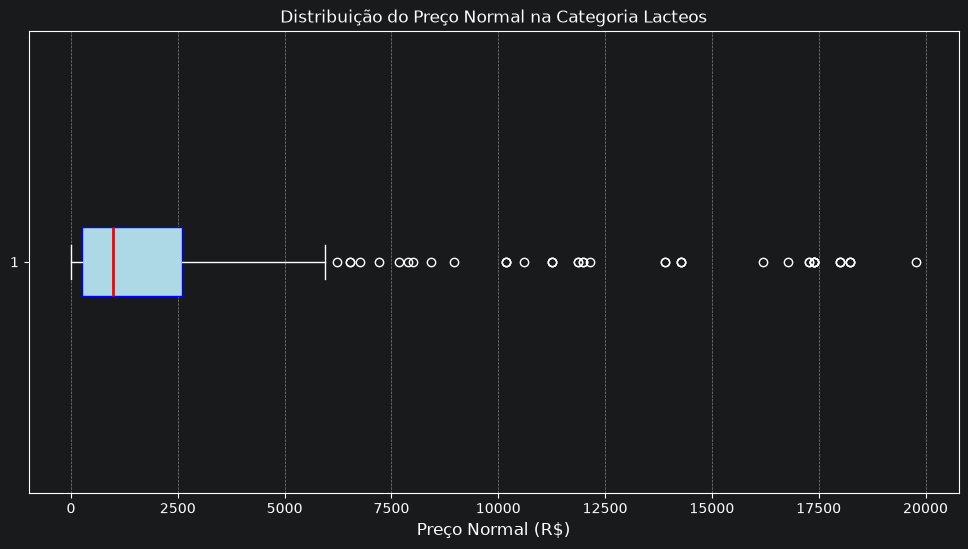

In [134]:
#Seu código aqui
#Filtrando a categoria escolhida
df_lacteos = df.loc[df['Categoria'] == 'lacteos']


#Criando o boxplot
plt.figure(figsize = (12,6))

plt.boxplot(df_lacteos['Preco_Normal'], orientation='horizontal', patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'), medianprops=dict(color='red', linewidth=2))

plt.title('Distribuição do Preço Normal na Categoria Lacteos')
plt.xlabel('Preço Normal (R$)', fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Análise do Boxplot:

· **Distribuição**: A distribuição dos preços em Lácteos é fortemente **assimétrica à direita** (assimetria positiva). Podemos ver isso porque a "caixa" (que representa 50% dos dados centrais) está espremida bem à esquerda, perto do zero. A linha vermelha (que é a mediana) está bem à esquerda, confirmando que a maioria dos produtos é barata.

· **Outliers**: Foram identificados **muitos outliers** (os inúmeros pontinhos isolados que se estendem bem para a direita, chegando perto de 20.000).

**Interpretação**: O boxplot mostra claramente que o consumidor típico de lácteos compra produtos de baixo valor (a caixa concentrada à esquerda). Porém, existem produtos muito caros (os outliers) que fogem completamente do padrão da prateleira. Esses pontos distantes são, na sua maioria, os "Packs com 12 unidades" de leite e as latas de leite em pó, que possuem alto valor agregado e puxam a média para cima.

# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

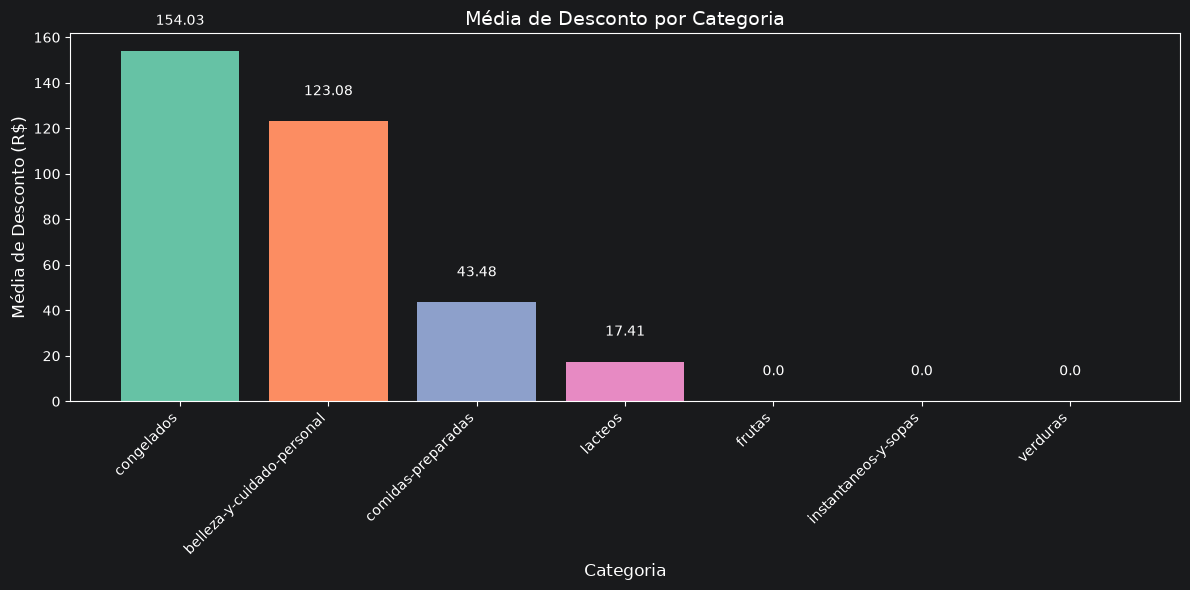

In [135]:
# Seu código aqui
#Calculando a média de desconto por categoria
media_desconto = df.groupby('Categoria')['Desconto'].mean().sort_values(ascending=False)


#Criando o gráfico
plt.figure(figsize = (12,6))


#Paleta de cores para fins estéticos
barras = plt.bar(media_desconto.index, media_desconto.values, color=plt.cm.Set2(range(len(media_desconto))))


#Título, rótulos e rotação do eixo x
plt.title('Média de Desconto por Categoria', fontsize = 14)
plt.xlabel('Categoria', fontsize = 12)
plt.ylabel('Média de Desconto (R$)', fontsize = 12)


plt.xticks(rotation=45, ha='right')


#Adicionando os valores em cima das barras para fins visuais
for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + 10, round(yval, 2), ha='center', va='bottom', fontsize = 10)


#Ajustando o layout para evitar cortes
plt.tight_layout()
plt.show()

# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [136]:
# Seu código aqui
#Agrupando os dados por Categoria e Marca, calculando a média de desconto
df_mapa = df.groupby(['Categoria', 'Marca'])['Desconto'].mean().reset_index()


#Filtrando por descontos acima de 0
df_mapa = df_mapa[df_mapa['Desconto'] > 0]


#Criando o mapa interativo Treemap
fig = px.treemap(df_mapa, path=['Categoria', 'Marca'], values='Desconto', color='Desconto', color_continuous_scale='Blues', title='Mapa Interativo: Média de Desconto por Categoria e Marca', hover_data={'Desconto': ':.2f'})


#Ajustando o layout para fins estéticos
fig.update_layout(margin=dict(r=25, t=50, b=25, l=25))


fig.show(renderer='browser')